# HAM10000 Skin Lesion Classification

## 01 - Dataset Exploration

### Objective
The objective of this notebook is to understand the
HAM10000 dataset through exploratory data analysis.

### Tasks
1. Load the dataset.
2. Understand dataset dimensions.
3. Inspect column information.
4. Check missing values.
5. Check duplicate records.
6. Analyze target class distribution.
7. Explore categorical and numerical features.
8. Visualize sample skin lesion images.

In [1]:
# Import libraries for data analysis and visualization

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from PIL import Image

# Set visualization style
sns.set_style("whitegrid")

# Display all columns in pandas
pd.set_option("display.max_columns", None)

# Set default figure size
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Define the main data directory
DATA_DIR = Path("../data")

# Define metadata file path
METADATA_PATH = DATA_DIR / "HAM10000_metadata.csv"

# Define image directories
IMAGE_DIR_1 = DATA_DIR / "HAM10000_images_part_1"
IMAGE_DIR_2 = DATA_DIR / "HAM10000_images_part_2"

# Check whether paths exist
print("Metadata exists:", METADATA_PATH.exists())
print("Image folder 1 exists:", IMAGE_DIR_1.exists())
print("Image folder 2 exists:", IMAGE_DIR_2.exists())

Metadata exists: True
Image folder 1 exists: True
Image folder 2 exists: True


In [3]:
# Load HAM10000 metadata into a pandas DataFrame

df = pd.read_csv(METADATA_PATH)

# Display first five records
df.head()

,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


In [4]:
# Display number of rows and columns

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 10015
Number of columns: 7


In [5]:
# Display column names

print("Dataset Columns:")
print(df.columns.tolist())

# Display data types and non-null counts
df.info()

Dataset Columns:
['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10015 entries, 0 to 10014
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   lesion_id     10015 non-null  object 
 1   image_id      10015 non-null  object 
 2   dx            10015 non-null  object 
 3   dx_type       10015 non-null  object 
 4   age           9958 non-null   float64
 5   sex           10015 non-null  object 
 6   localization  10015 non-null  object 
dtypes: float64(1), object(6)
memory usage: 547.8+ KB


In [6]:
# Generate statistical summary for numerical columns

df.describe()

,age
count,9958.000000
mean,51.863828
std,16.968614
min,0.000000
25%,40.000000
50%,50.000000
75%,65.000000
max,85.000000


In [7]:
# Calculate missing values in each column

missing_values = df.isnull().sum()

# Calculate missing value percentage
missing_percentage = (missing_values / len(df)) * 100

# Create a summary table
missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage
})

missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
)

,Missing Values,Missing Percentage
age,57,0.569146
lesion_id,0,0.000000
image_id,0,0.000000
dx,0,0.000000
dx_type,0,0.000000
sex,0,0.000000
localization,0,0.000000


In [8]:
# Check duplicate records

duplicate_count = df.duplicated().sum()

print("Total duplicate records:", duplicate_count)

# Check duplicate image IDs
print("Duplicate image IDs:", df["image_id"].duplicated().sum())

Total duplicate records: 0
Duplicate image IDs: 0


In [9]:
# Count the number of images in each diagnostic class

class_counts = df["dx"].value_counts()

print(class_counts)

dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


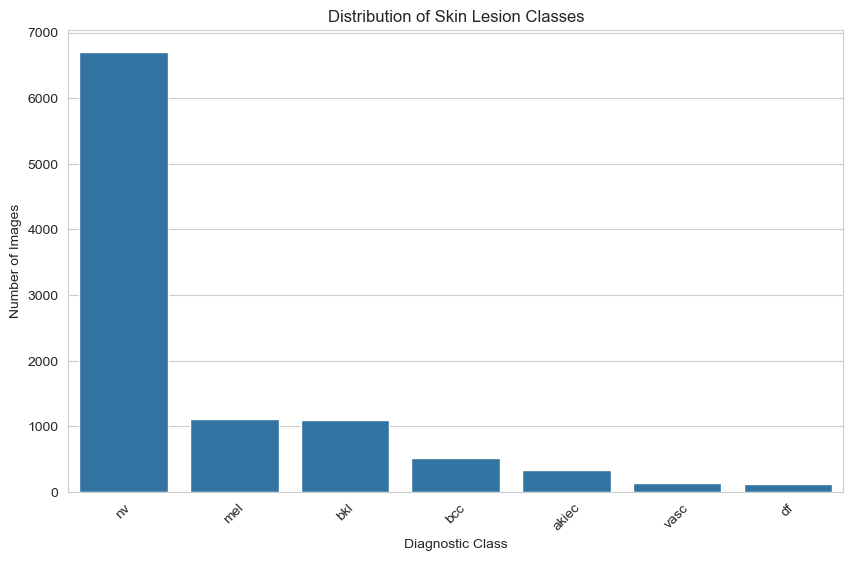

In [10]:
# Plot class distribution

plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="dx",
    order=df["dx"].value_counts().index
)

plt.title("Distribution of Skin Lesion Classes")
plt.xlabel("Diagnostic Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)

plt.show()

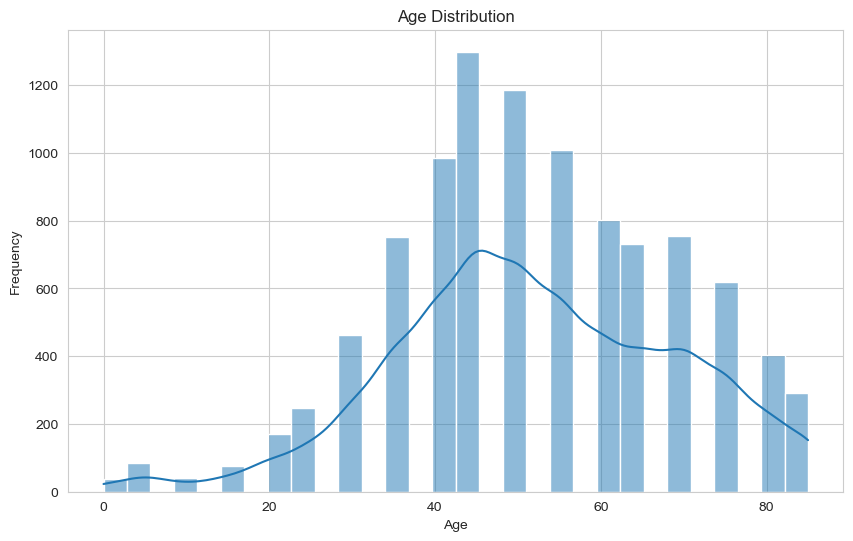

In [11]:
# Analyze patient age distribution

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="age",
    bins=30,
    kde=True
)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

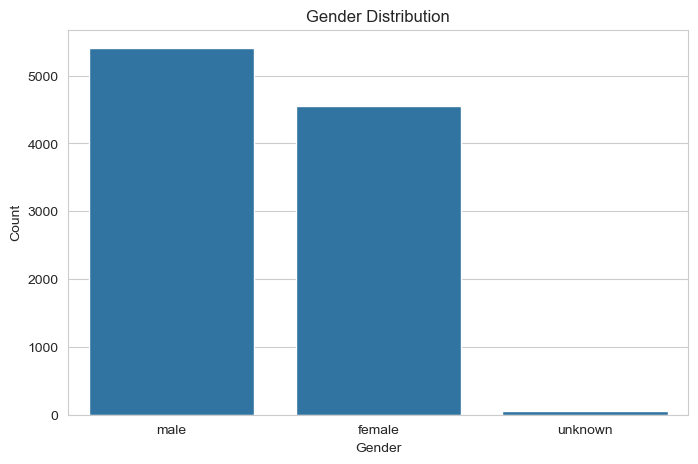

In [12]:
# Analyze gender distribution

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="sex"
)

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Count")

plt.show()

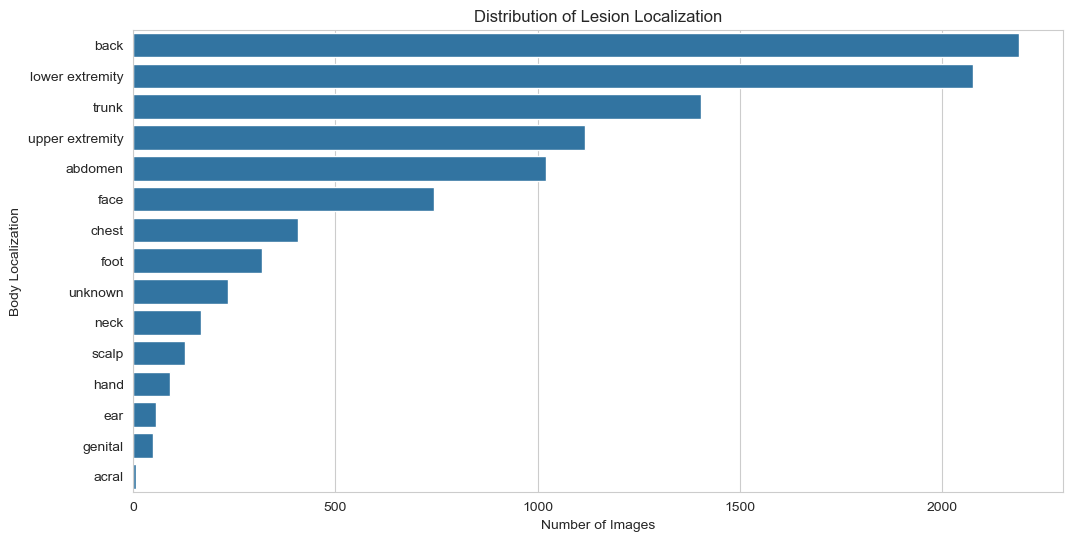

In [13]:
# Analyze lesion localization

plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y="localization",
    order=df["localization"].value_counts().index
)

plt.title("Distribution of Lesion Localization")
plt.xlabel("Number of Images")
plt.ylabel("Body Localization")

plt.show()

In [14]:
# Create a dictionary to map image IDs to image paths

image_paths = {}

for folder in [IMAGE_DIR_1, IMAGE_DIR_2]:

    for image_path in folder.glob("*.jpg"):

        image_id = image_path.stem

        image_paths[image_id] = image_path

# Map image paths to metadata
df["image_path"] = df["image_id"].map(image_paths)

print("Total metadata records:", len(df))
print("Images successfully mapped:", df["image_path"].notna().sum())
print("Images not found:", df["image_path"].isna().sum())

Total metadata records: 10015
Images successfully mapped: 10015
Images not found: 0


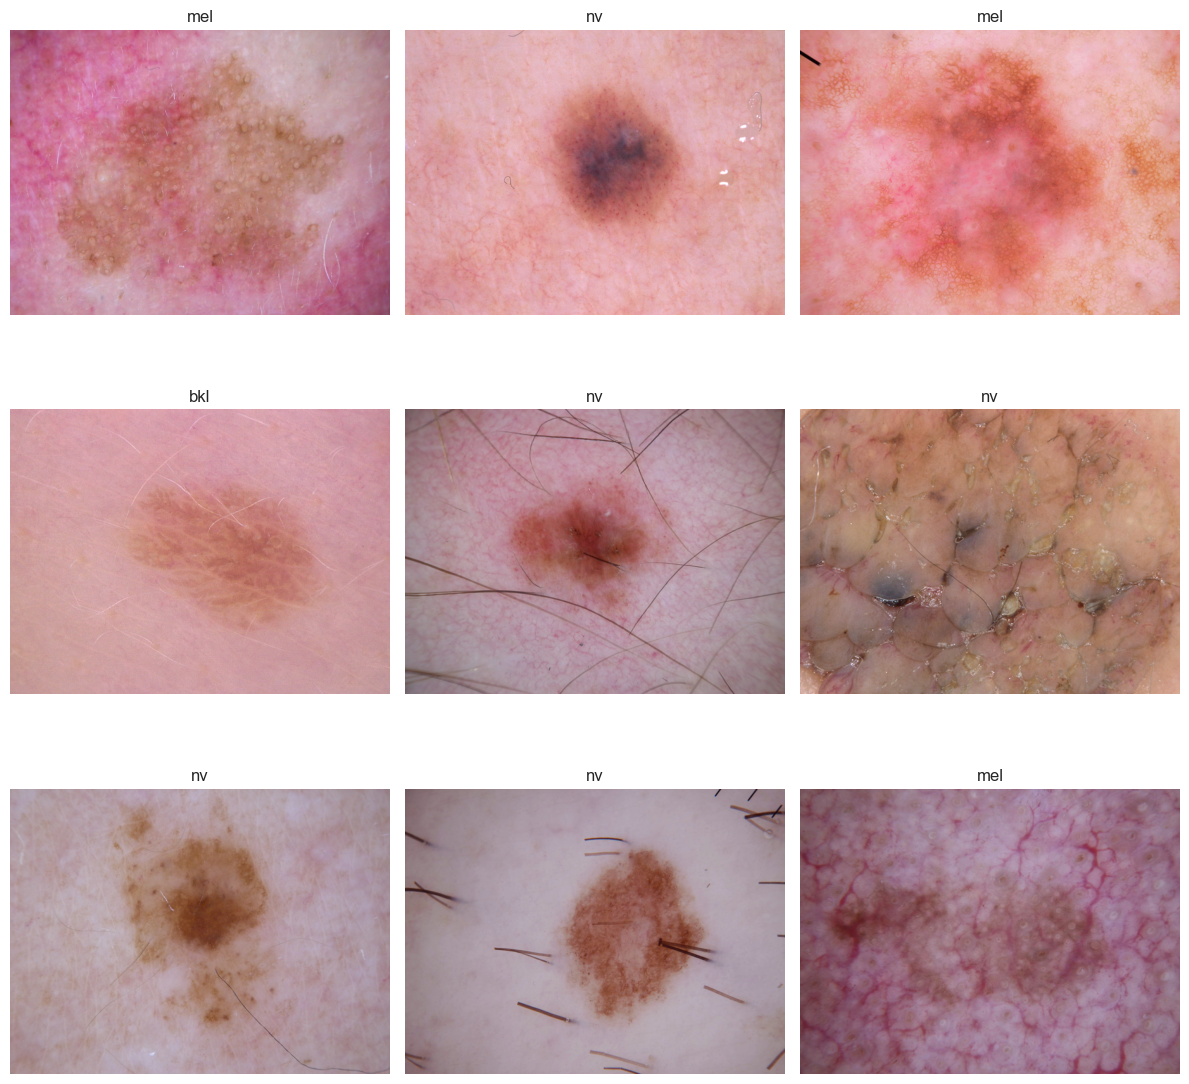

In [15]:
# Display sample skin lesion images from the dataset

sample_data = df.dropna(subset=["image_path"]).sample(
    n=9,
    random_state=42
)

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for ax, (_, row) in zip(axes.flatten(), sample_data.iterrows()):

    # Open image
    image = Image.open(row["image_path"])

    # Display image
    ax.imshow(image)

    # Add diagnostic class as title
    ax.set_title(row["dx"])

    ax.axis("off")

plt.tight_layout()
plt.show()

In [16]:
# Create outputs directory if it does not exist

OUTPUT_DIR = Path("../outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save the explored metadata
df.to_csv(
    OUTPUT_DIR / "HAM10000_explored.csv",
    index=False
)

print("Explored dataset saved successfully!")

Explored dataset saved successfully!


## EDA Observations

1. The dataset contains seven diagnostic classes.
2. The dataset has an imbalanced class distribution.
3. Missing values are present in some metadata columns.
4. Patient age and lesion localization provide
   additional information about the dataset.
5. Image paths are mapped using image IDs.
6. Sample images are visualized to understand
   the image data.

## Conclusion

Exploratory Data Analysis helps us understand the
dataset structure, data quality, class distribution,
and image characteristics before preprocessing.